<h1>Workshop 5 - Data Analysis</h1>

In this Workshop, rather than having all our code in the Jupyter Notebook, we'll load up some Python from a pre-written module called <b>arduino</b>.

We'll then build on the data visualisation and code structure material that you studied in Workshops 2 and 3 to look at how to perform more complicated data visualisation and analysis in Python.

<h1>Hacking Activity 1 - Talking to Your Nicla via the Arduino Module</h1>

<b>For this exercise, you'll need to be connected to your MKR WiFi 1010, and have both it and your Nicla set up according to the instructions given in Workshop 5, Arduino Activity 1.</b> 

<b>You'll also need to clone the GitHub repository containing the Python according to the instructions given in Workshop 5, GitHub Activity 1.</b>

Just as in previous weeks, your task is to get some semi-familiar Python code talking to your Nicla. 

This week, rather than modifying a block of code in the notebook, most of your code will be in a separate Python file that you'll import and use via the notebook.

In [2]:
from arduino import arduino as rd 

nicla = rd.arduino_connect('/dev/cu.usbmodem11101')
column_titles = ['time', 'temp', 'pressure', 'gas']
data = rd.arduino_read(column_titles, nicla, n_readings=10, r_readings=50)
rd.arduino_save(data, column_titles)
data

/dev/cu.wlan-debug - n/a
/dev/cu.Bluetooth-Incoming-Port - n/a
/dev/cu.usbmodem11101 - Arduino MKR WiFi 1010
Failed to read data index 0 (attempt number 1 out of 100). Trying again...
Failed to read data index 0 (attempt number 2 out of 100). Trying again...
Failed to read data index 0 (attempt number 3 out of 100). Trying again...
Failed to read data index 0 (attempt number 4 out of 100). Trying again...
Failed to read data index 0 (attempt number 5 out of 100). Trying again...
Failed to read data index 0 (attempt number 6 out of 100). Trying again...
Failed to read data index 0 (attempt number 7 out of 100). Trying again...
Failed to read data index 0 (attempt number 8 out of 100). Trying again...
Failed to read data index 0 (attempt number 9 out of 100). Trying again...
Failed to read data index 0 (attempt number 10 out of 100). Trying again...
Failed to read data index 1 (attempt number 1 out of 100). Trying again...
Failed to read data index 2 (attempt number 1 out of 100). Trying

array([[  209.  ,    28.31,  1005.41, 19733.  ],
       [  359.  ,    28.31,  1005.41, 19586.  ],
       [  489.  ,    28.31,  1005.4 , 19586.  ],
       [  630.  ,    28.31,  1005.39, 19549.  ],
       [  780.  ,    28.31,  1005.39, 19476.  ],
       [  910.  ,    28.31,  1005.39, 19476.  ],
       [ 1060.  ,    28.3 ,  1005.4 , 19458.  ],
       [ 1190.  ,    28.3 ,  1005.4 , 19458.  ],
       [ 1330.  ,    28.3 ,  1005.4 , 19494.  ],
       [ 1470.  ,    28.3 ,  1005.39, 19494.  ]])

Get the above code to save three .csv files containing 10, 100, and 1000 data points to your computer.

<b>Two things to note:</b> 

1. Every time you modify arduino.py, remember to save it, and to restart the Python kernel in VS Code.
1. You'll find you get data that's a bit more interesting to work with if you gently jiggle your Arduino around while it's measuring.

<h1>Take a Break</h1>
Maybe there will be snacks. Maybe there will be cat photos. No promises though.

<h1>Python Activity 1 - Revision of Simple Plotting</h1>



<h3>1.1 Data Filtering and Basic Plotting Revision</h3>
Let's quickly review basic data tidying and plotting in <b>pandas</b> and <b>matplotlib</b> before doing some more complicated analysis.

Start by importing some useful modules:

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
mpl.rcParams['axes.formatter.useoffset'] = False    # Remove annoying auto-offset

First - we'll use pandas to load our data and use its describe() function to take a quick look at our data:

In [4]:
data = pd.read_csv('./data_1000.csv', index_col=0)
data

,time,temp,pressure,gas
0,509.0,23.67,1020.49,24891.0
1,719.0,23.67,1020.49,25054.0
2,869.0,23.67,1020.53,24817.0
3,1029.0,23.69,1020.53,24891.0
4,1159.0,23.69,1020.53,24891.0
...,...,...,...,...
995,138693.0,23.23,1020.46,24876.0
996,138833.0,23.23,1020.46,24920.0
997,138963.0,23.23,1020.46,24920.0
998,139113.0,23.25,1020.46,24935.0


Now - remove statistical outliers - in the example below, we remove data from the lower and highest percentile:

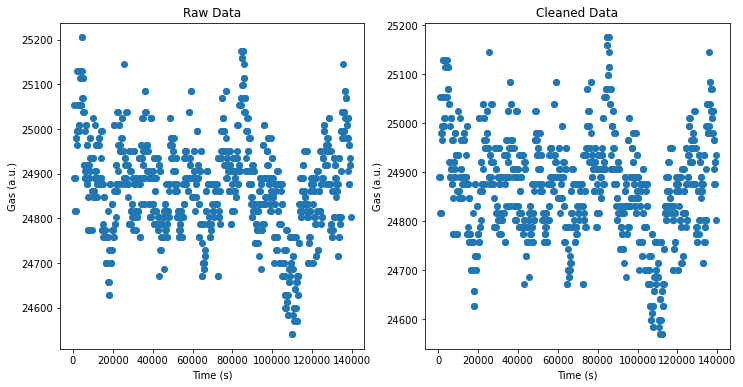

In [5]:
lower_bound = data['gas'].quantile(0.0001)
upper_bound = data['gas'].quantile(0.9999)

data_gas_clean = data[(data['gas'] > lower_bound) & (data['gas'] < upper_bound)]

fig = plt.figure(figsize=(12, 6))
ax1 = fig.add_subplot(121)
ax1.scatter(data['time'], data['gas'])
ax1.set_xlabel('Time (s)')
ax1.set_ylabel('Gas (a.u.)')
ax1.set_title('Raw Data')

ax2 = fig.add_subplot(122)
ax2.scatter(data_gas_clean['time'], data_gas_clean['gas'])
ax2.set_xlabel('Time (s)')
ax2.set_ylabel('Gas (a.u.)')
ax2.set_title('Cleaned Data')
plt.show()


<h3>Python Exercise 1</h3>

1. Repeat the above with the other sensors that you're reading from (pressure and gas, if you're using the code given to you!) - save plots of the data from all three sensors.

<h1>Python Activity 2 - More Complex Plotting</h1>

Now let's do some proper data visualisation and analysis.



<h3>2.1 - Histograms</h3>
Based on your results from Python Exercise 1, pick a nice noisy dataset to work with. In the following examples, we'll use the gas sensor, but temperature and pressure may work equally well.

Let's start by visualising the noise in your data, after we've excluded outliers such as 0 values:

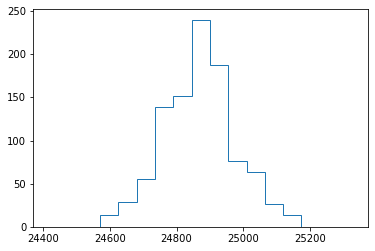

In [6]:
data = pd.read_csv('./data_1000.csv', index_col=0)

lower_bound = data['gas'].quantile(0.001)
upper_bound = data['gas'].quantile(0.999)
data_clean = data[(data['gas'] > lower_bound) & (data['gas'] < upper_bound)]

counts, bins = np.histogram(data_clean['gas'], bins=11)

fig = plt.figure()
ax = fig.add_subplot(111)
ax.stairs(counts, bins)
ax.set_xlim(bins[0]-200, bins[-1]+200)
plt.show()

<h1>Python Exercise 2.1</h1>
First - modify the quantiles you're exluding so that you're only excluding outliers. Your may find you don't need to exlude outliers at all (this was the case for the dataset that I took!)

Now - search the internet, stackoverflow, and even ChatGPT to add the following features to your graph:

1. Change the number of bars to suit your data.
1. Title, x- and y-labels.
1. Modify the x-tick label font size to look nicer.
1. Make the lines on bars thicker.
1. Change the fill and border colours for the bars in your plot.
1. Save the plot when you're happy with it.
1. Run through this page - https://numpy.org/doc/stable/reference/generated/numpy.histogram.html - and find out how to normalise your histogram

<h3>2.2 - Curve Fitting</h3>
Now let's look at using a library called <b>scipy</b> to fit a curve to our data. 

A Gaussian (or 'normal') distribution is defined by the following equation:

$$f(x; \sigma, \mu) = A \ \mathrm{exp} \left ( \frac{-(x-\mu)^2}{2\sigma^2} \right )$$

The code we use to fit this equation to our data is given below. 

Read through the comments, search the internet and use the print command to understand any functions that are unfamiliar to you:

25205.0 108.61805032247567 24869.245
[  212.90664771    99.77207044 24867.23984472]


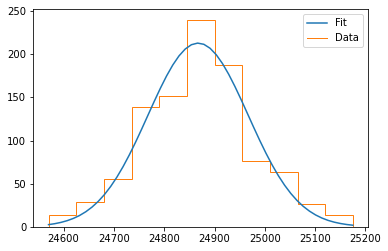

In [14]:
from scipy.optimize import curve_fit

# Define the function we're fitting
def gaussian(x, a, sigma, mu):
    return a*np.exp((-1*(x - mu)**2)/(2*sigma**2))

# Calculate the mid-points of the histogram bins - so convert it to a scatter graph
bins_midpoint = (bins[:-1] + bins[1:]) / 2.


# We need to feed the fit algorithm initial guesses of the values in our function
# a_guess, std_guess, mean_guess = 200, 200, 25000

a_guess, std_guess, mean_guess = data['gas'].max(), data['gas'].std(), data['gas'].mean()
print(a_guess, std_guess, mean_guess)
fit_params = np.array([a_guess, std_guess, mean_guess])

popt, pcov = curve_fit(gaussian, bins_midpoint, counts, p0=fit_params)
print(popt)

# Plot the data and the fit
fig = plt.figure()
ax = fig.add_subplot(111)
ax.plot(np.linspace(bins[0], bins[-1]), gaussian(np.linspace(bins[0], bins[-1]), popt[0], popt[1], popt[2]), label='Fit')
ax.stairs(counts, bins, label='Data')
plt.legend()
plt.show()



<h1>Python Exercise 2.2</h1>

1. Modify the initial guesses for your fit parameters so your data is well fitted by your Gaussian.

1. Use [ColorBrewer](https://colorbrewer2.org/) to pick a color scheme for your histogram and line of fit that is color-blind-friendly.


<h3>Stretch Exercises</h3>
<b>You're not expected to tackle these in the workshop, but try them at home.</b>

1. The way we calculate the mid-point of the bins is a little tricky - are you certain it's worked? How would check? How would you write a more "human-readable" version using lists and a 'for' loop?

1. Instead of a Gaussian, fit a Lorentzian (sometimes called a Cauchy Distribution) to your data:
$$f(x; x_0, \gamma) = \frac{}{} \left[ \frac{\gamma}{(x-x_0)^2 + \gamma^2} \right ]$$
Where $x_0$ and $\gamma$ are the peak location and half-width of your function, respectively.

Which distribution fits your data better - Gaussian or Lorentzian?

<h1>Take Another Break</h1>
It's 3 o'clock on a Friday. Nobody else is working hard, why should you?

<h1>Python Activity 3</h1>
Sometimes you'll want to put multiple plots in a single figure. We'll start by referring to them one-by-one (painful!). You homework will be to explore a cleverer way of editing them.

We'll use matplotlib's subplots command - https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html

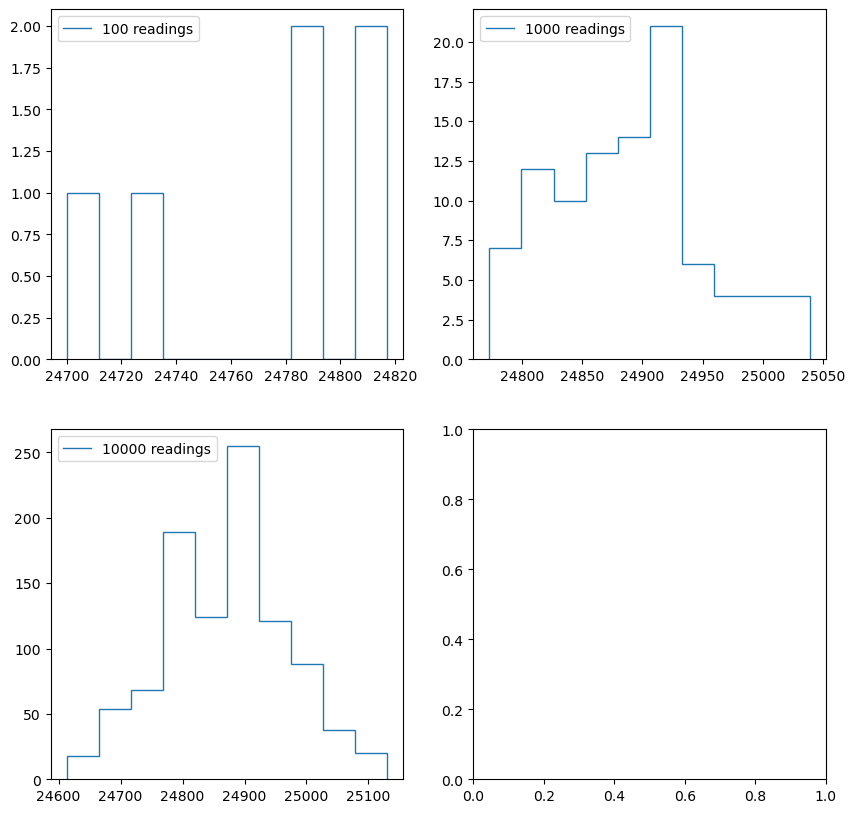

In [26]:
fig, axs = plt.subplots(2, 2, figsize=(10,10))

data = pd.read_csv('./data_10.csv', index_col=0)
lower_bound = data['gas'].quantile(0.01)
upper_bound = data['gas'].quantile(0.99)
data_clean = data[(data['gas'] > lower_bound) & (data['gas'] < upper_bound)]
counts, bins = np.histogram(data_clean['gas'])
axs[0,0].stairs(counts, bins, label='100 readings')
axs[0,0].legend()

data = pd.read_csv('./data_100.csv', index_col=0)
counts, bins = np.histogram(data['gas'])
lower_bound = data['gas'].quantile(0.01)
upper_bound = data['gas'].quantile(0.99)
data_clean = data[(data['gas'] > lower_bound) & (data['gas'] < upper_bound)]
counts, bins = np.histogram(data_clean['gas'])
axs[0,1].stairs(counts, bins, label='1000 readings')
axs[0,1].legend()

data = pd.read_csv('./data_1000.csv', index_col=0)
lower_bound = data['gas'].quantile(0.01)
upper_bound = data['gas'].quantile(0.99)
data_clean = data[(data['gas'] > lower_bound) & (data['gas'] < upper_bound)]
counts, bins = np.histogram(data_clean['gas'])
axs[1,0].stairs(counts, bins, label='10000 readings')
axs[1,0].legend()

<h1>Python Exercise 3.1</h1>

1. Add lines of best fit to all 3 plots.

1. Figure out how to remove the empty fourth plot.

<h3>Stretch Exercise</h3>
See that fourth graph? Use it to plot all three histograms on the same graph.

You'll want to normalise them and offset them by a constant value so you can see all 3 graphs in the same plot. 

<b>What does normalise mean?</b>

It means that, instead of plotting the total number of measurements, you instead plot the histograms so either the maximum value of the plot is 1, or the total area under the histogram is 1 (this is called a probability density function in the link below). You can learn about how to normalise histograms here:
https://numpy.org/devdocs/reference/generated/numpy.histogram.html

<h1>Homework - Making Your Code DRY</h1>
We run a lot of the same code over and over again in that last exercise, don't we? This is bad - it makes our code hard to read and lots of work to edit. 

Let's look at some ways to make the code [dry](https://en.wikipedia.org/wiki/Don%27t_repeat_yourself)


<h3>4.1 - Figuring out what files are in a directory</h3>
Rather than specifying what files to run our analysis on, let's automate finding the files based on a shared trait that is unique to them - in this case, the file format.

In [7]:
# First - let's put together a list of files 
import os
files_all = os.listdir('./')    # Files in the directory that this code is in
files = [file for file in files_all if '.csv' in file]    # Remove files from the list that aren't .csv files
print(files)

['data_10.csv', 'data_100.csv', 'data_1000.csv']


<h3>4.2 - Using Loops to Set Plot Properties</h3>
Instead of referring to our plots one-by-one, we can use a for loop to refer to them in a single line of code. In many cases, we don't even have to enter the data manually. Let's look at an example of how to do this below:

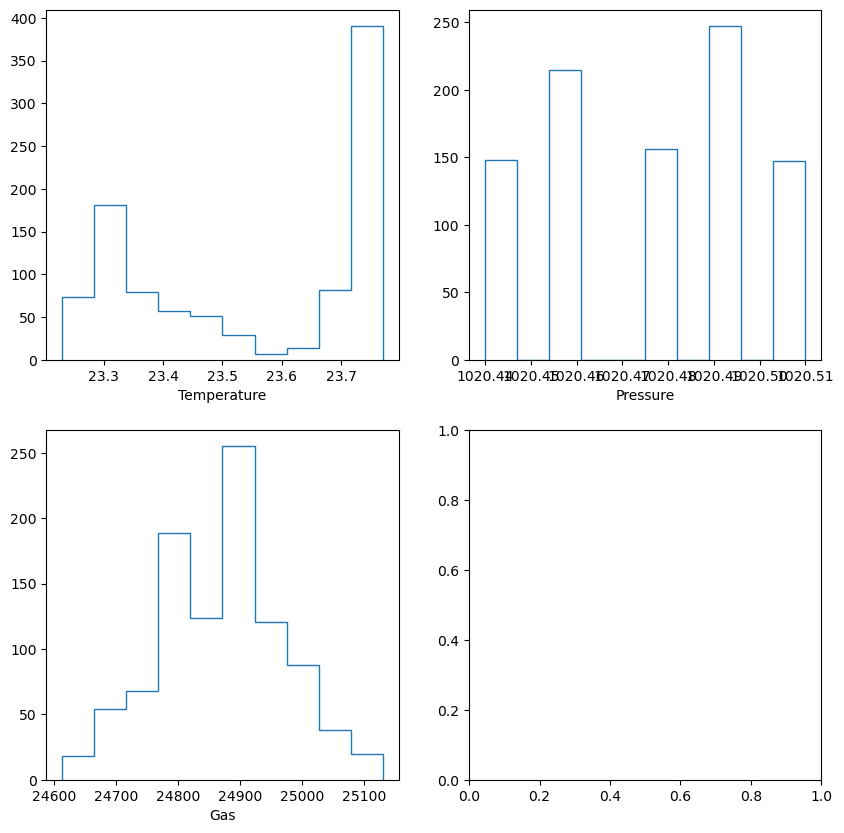

In [9]:
def hist_calc(data_in, var_in, lq_in=0.01, uq_in=0.99):
    # Add a comment to say what this function does
    counts_out, bins_out = np.histogram(data_in[var_in])
    lower_bound = data_in[var_in].quantile(lq_in)
    upper_bound = data_in[var_in].quantile(uq_in)
    data_clean = data_in[(data[var_in] > lower_bound) & (data[var_in] < upper_bound)]
    counts_out, bins_out = np.histogram(data_clean[var_in])
    return counts_out, bins_out

data = pd.read_csv('data_1000.csv', index_col=0)
column_titles = data.columns.tolist()
column_titles = column_titles[1:]
n_vars = len(column_titles)
var_names = ['Temperature', 'Pressure', 'Gas']

nrows = int(np.ceil(np.sqrt(n_vars)))
ncols = int(n_vars // nrows + 1)
fig, axs = plt.subplots(nrows, ncols, figsize=(5*ncols, 5*nrows))

for n, sensor in enumerate(column_titles):
    i = n // ncols
    j = n % ncols
    counts, bins = hist_calc(data, column_titles[n])
    axs[i,j].stairs(counts, bins)
    axs[i,j].set_xlabel(var_names[n])

# plt.show()


<h3>Python Exercise 4.1</h3>

1. Run through the above code adding comments saying what each line does - you'll want to a combination of google searches and the print command.

1. Figure out how to remove the pesky empty final graph. I thought [this was a really nice guide](https://engineeringfordatascience.com/posts/matplotlib_subplots/) on some nice approaches to this.

1. Use your for loop to modify the appearance of your plots, focus on clear presentation and aesthetic appeal.

1. Use a second 'for' loop to produce plots for all 3 of the data files you saved earlier (the ones containing 10, 100, and 1000 data points).

<b>End of Workshop</b>
